In [ ]:
import os
import sys
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules

if IN_COLAB:
    GITHUB_USER = "SinghSahiljit44"  # Es. sahiljit
    REPO_NAME = "Weather_forecasting"
    REPO_URL = f"https://github.com/{GITHUB_USER}/{REPO_NAME}.git"

    # Clona la repository se non è già stata clonata nella sessione
    if not os.path.exists(REPO_NAME):
        !git clone {REPO_URL}

    # Cambia la directory di lavoro nella root del progetto
    os.chdir(REPO_NAME)
    
    # Installa le dipendenze necessarie nell'ambiente di Colab
    %pip install -q -r requirements.txt
    
    PROJECT_ROOT = Path.cwd()
else:
    # --- CONFIGURAZIONE LOCALE  ---
    PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
    os.chdir(PROJECT_ROOT)

if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

print(f" [OK] Ambiente rilevato: {'Google Colab' if IN_COLAB else 'Locale'}")
print(f" [OK] Directory di lavoro impostata a: {Path.cwd()}")

 [OK] Ambiente rilevato: Locale
 [OK] Directory di lavoro impostata a: /home/matteo/Documents/GitHub/Weather_forecasting


# First off, Data preprocessing
In this next cell, we will preprocess data so that it will be available in the next steps for each model.

In [ ]:
import numpy as np
import pandas as pd
import srzc.utils.metrics as metrics
import matplotlib.pyplot as plt

from src.data.preprocessing import load_daily
from src.utils.split import Split

data = load_daily()

# Seasonality
doy = data.index.day_of_year
data["doy_sin"] = np.sin(2 * np.pi * doy / 365.25) 
data["doy_cos"] = np.cos(2 * np.pi * doy / 365.25)

# Recent past temperature: only values up to day t
# Moving averages, takes average of the last 7 days, including t
for k in range(1, 3):
    data[f"t2m_lag{k}"]     = data["t2m_mean"].shift(k)
    data[f"tp_mm_lag{k}"]   = data["tp_mm"].shift(k)
data["t2m_roll7"] = data["t2m_mean"].rolling(7).mean() # recent trend
data["t2m_roll30"] = data["t2m_mean"].rolling(30).mean() # background level, how warm is this period of the year

'''
We sure do not love climate change, but we need to acknowledge it!
This next feature is fundamental since it lets the model learn about 
the warming trend we've been feeling in these 30 years.
'''
data["year"] = data.index.year + (data.index.day_of_year - 1) / 365.25  # fractional year

features = data.columns.array

split = Split(data)


### Coverage by season
BayesianRidge assumes the same noise level all year, so the interval has about the same width in every season. If errors are larger in some seasons, the 95% interval will be too narrow there and too wide elsewhere, even when the overall coverage is close to 95%.

In [ ]:
SEASONS = {12: "Winter", 1: "Winter", 2: "Winter",
           3: "Spring", 4: "Spring", 5: "Spring",
           6: "Summer", 7: "Summer", 8: "Summer",
           9: "Autumn", 10: "Autumn", 11: "Autumn"}

# Season of the forecast target day t+h
def season(y):
    return (y.index + pd.Timedelta(days=h)).month.map(SEASONS)

def season_coverage(y, y_pred, y_std):
    inside = pd.Series(np.abs(y - y_pred) <= 1.96 * y_std, index=y.index)
    return inside.groupby(season(y)).mean()

def season_mae(y, y_pred):
    return (y - y_pred).abs().groupby(season(y)).mean()

season_table = pd.DataFrame({
    "Validation coverage": season_coverage(y_val, y_val_pred_bayes, y_val_std),
    "Test coverage": season_coverage(y_test, y_test_pred_bayes, y_test_std),
    "Validation MAE (°C)": season_mae(y_val, y_val_pred_bayes),
    "Test MAE (°C)": season_mae(y_test, y_test_pred_bayes),
    "Mean 95% interval width (°C)": pd.Series(2 * 1.96 * y_test_std, index=y_test.index).groupby(season(y_test)).mean(),
}).reindex(["Winter", "Spring", "Summer", "Autumn"]).rename_axis("Season")

display(season_table.round(3))

,Validation coverage,Test coverage,Validation MAE (°C),Test MAE (°C),Mean 95% interval width (°C)
Season,,,,,
Winter,0.947,0.964,1.195,1.022,5.639
Spring,0.924,0.951,1.214,1.045,5.640
Summer,0.938,0.946,1.220,1.202,5.640
Autumn,0.967,0.948,0.890,1.040,5.640


## Support Vector Regression
SVR fits a function that ignores errors smaller than `epsilon` and penalises larger ones linearly, so it behaves like an MAE-based model and is robust to outliers. The kernel decides which shape the function can take. Same features, split and horizon `h` as the linear models.

### Kernel
Each kernel is tried with a small hyperparameter grid and scored on the validation set only. The linear kernel uses `LinearSVR`: same model, much faster than `SVR(kernel="linear")` on 10k samples.

In [ ]:
from joblib import Parallel, delayed
from sklearn.svm import SVR, LinearSVR

# Candidate kernels with a small hyperparameter grid each
candidates = (
    [("linear", {"C": C}) for C in (0.1, 1, 10)]
    + [("poly", {"degree": d, "C": C, "coef0": 1}) for d in (2, 3) for C in (0.1, 1, 10)]
    + [("rbf", {"C": C, "gamma": gamma}) for C in (1, 10, 100) for gamma in (0.003, 0.01, 0.03)]
)

def make_svr(kernel, params):
    if kernel == "linear":
        svr = LinearSVR(max_iter=20000, random_state=0, **params)
    else:
        svr = SVR(kernel=kernel, **params)
    return make_pipeline(StandardScaler(), svr)  # SVR needs scaled features

def svr_val_mae(kernel, params):
    svr = make_svr(kernel, params).fit(X_train, y_train)
    return mean_absolute_error(y_val, svr.predict(X_val))

# Fits run in parallel on all CPU cores
scores = Parallel(n_jobs=-1)(delayed(svr_val_mae)(kernel, params) for kernel, params in candidates)

kernel_scores = pd.DataFrame(
    [(kernel, str(params), score) for (kernel, params), score in zip(candidates, scores)],
    columns=["Kernel", "Best params", "Val MAE"],
)

# Best configuration of each kernel, with the linear regression as reference
kernel_table = kernel_scores.loc[kernel_scores.groupby("Kernel")["Val MAE"].idxmin()].set_index("Kernel")
kernel_table.loc["(Linear Regression)"] = ["-", mean_absolute_error(y_val, y_val_pred)]

display(kernel_table.sort_values("Val MAE").round(4))

NameError: name 'make_pipeline' is not defined

### Choosing the RBF kernel
- **Sigmoid** is the worst: it is not a valid (positive semi-definite) kernel in general, and it saturates on standardized features.
- **Linear** is essentially the linear regression with an MAE-like loss, so it can't capture nonlinear effects.
- **Polynomial and RBF** are tied on validation. We pick **RBF** because it stays smooth and bounded: a polynomial grows without limit outside the training range, which is risky when the test years are warmer than the training years. RBF also has two clear knobs: `gamma` (how local/wiggly the function is) and `C` (how much errors are penalised).

Below, `C` and `gamma` are tuned on a finer grid, again on validation only; the test set is used once at the end.

In [ ]:
rbf_grid = [{"C": C, "gamma": gamma} for C in (0.3, 1, 3, 10, 30) for gamma in (0.001, 0.003, 0.01, 0.03)]
rbf_scores = Parallel(n_jobs=-1)(delayed(svr_val_mae)("rbf", params) for params in rbf_grid)

# Validation MAE for every C / gamma pair
rbf_table = pd.DataFrame(rbf_grid).assign(**{"Val MAE": rbf_scores})
display(rbf_table.pivot(index="C", columns="gamma", values="Val MAE").round(4))

best_rbf = rbf_grid[int(np.argmin(rbf_scores))]
print("Best RBF parameters:", best_rbf)

# Refit the best configuration and evaluate it once on validation and test
svr = make_svr("rbf", best_rbf).fit(X_train, y_train)
y_val_pred_svr = svr.predict(X_val)
y_test_pred_svr = svr.predict(X_test)

# Add SVR to the comparison table of the linear models
comparison.loc[("SVR (RBF)", "Validation"), ["MAE", "RMSE", "R²"]] = list(metrics(y_val, y_val_pred_svr).values())
comparison.loc[("SVR (RBF)", "Test"), ["MAE", "RMSE", "R²"]] = list(metrics(y_test, y_test_pred_svr).values())
display(comparison.round(4))

svr_results = pd.DataFrame({
    "Actual temperature (°C)": y_test,
    "Predicted temperature (°C)": y_test_pred_svr,
}, index=y_test.index)

display(svr_results.tail(10))

gamma,0.001,0.003,0.010,0.030
C,,,,
0.3,1.3483,1.2417,1.1891,1.1738
1.0,1.2211,1.1745,1.1434,1.1261
3.0,1.1665,1.1434,1.1151,1.0944
10.0,1.1396,1.1143,1.0891,1.0717
30.0,1.1182,1.0909,1.0716,1.0580


Best RBF parameters: {'C': 30, 'gamma': 0.03}


MAE    RMSE      R²  95% coverage
Linear Regression Validation  1.1297  1.4579  0.9645           NaN
                  Test        1.0769  1.3959  0.9683           NaN
BayesianRidge     Validation  1.1299  1.4585  0.9644        0.9438
                  Test        1.0778  1.3969  0.9682        0.9520
SVR (RBF)         Validation  1.0580  1.3926  0.9676           NaN
                  Test        1.0135  1.3330  0.9711           NaN

,Actual temperature (°C),Predicted temperature (°C)
date,,
2025-12-20,10.517791,10.622327
2025-12-21,10.487838,9.493041
2025-12-22,11.542017,10.187370
2025-12-23,9.799799,10.888021
2025-12-24,9.827432,8.171616
2025-12-25,10.215005,9.533841
2025-12-26,9.153858,9.899560
2025-12-27,7.735994,7.915703
2025-12-28,7.517165,7.588019


### SVR predictions on the test set
Left: last year of the test period, actual vs predicted temperature. Right: every test day, predicted against actual; points on the dashed line are perfect forecasts.

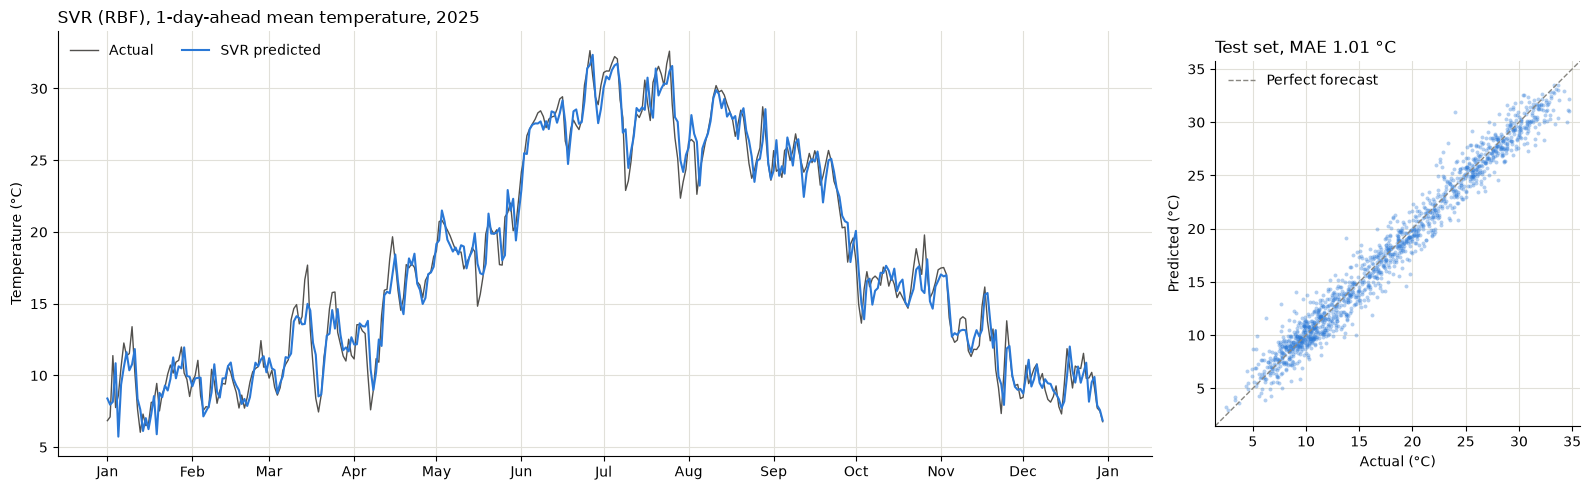

In [ ]:
svr_plot = svr_results.copy()
svr_plot.index = svr_plot.index + pd.Timedelta(days=h)
last_year = svr_plot.loc[str(svr_plot.index.year.max())]

fig, (ax_time, ax_scatter) = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [3, 1]})

ax_time.plot(last_year.index, last_year["Actual temperature (°C)"], color="#52514e", linewidth=1, label="Actual")
ax_time.plot(last_year.index, last_year["Predicted temperature (°C)"], color="#2a78d6", linewidth=1.5, label="SVR predicted")
ax_time.set_title(f"SVR (RBF), {h}-day-ahead mean temperature, {last_year.index.year[0]}", loc="left")
ax_time.set_ylabel("Temperature (°C)")
ax_time.xaxis.set_major_locator(mdates.MonthLocator())
ax_time.xaxis.set_major_formatter(mdates.DateFormatter("%b"))
ax_time.legend(frameon=False, loc="upper left", ncol=2)

lims = [svr_plot.min().min() - 1, svr_plot.max().max() + 1]
ax_scatter.plot(lims, lims, color="#898781", linewidth=1, linestyle="--", label="Perfect forecast")
ax_scatter.scatter(svr_plot["Actual temperature (°C)"], svr_plot["Predicted temperature (°C)"],
                   s=8, color="#2a78d6", alpha=0.35, linewidths=0)
ax_scatter.set_xlim(lims)
ax_scatter.set_ylim(lims)
ax_scatter.set_aspect("equal")
ax_scatter.set_title(f"Test set, MAE {mean_absolute_error(y_test, y_test_pred_svr):.2f} °C", loc="left")
ax_scatter.set_xlabel("Actual (°C)")
ax_scatter.set_ylabel("Predicted (°C)")
ax_scatter.legend(frameon=False, loc="upper left")

for ax in (ax_time, ax_scatter):
    ax.grid(color="#e1e0d9", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

plt.tight_layout()
plt.show()

# Precipitations
Base models to predict precipitations

## Occurrence and amount
Daily precipitation behaves very differently from temperature:
- **Most days are almost dry.** ERA5-Land spreads tiny amounts over many days: only about 6% of the days are exactly 0 mm, but 75% are below 1 mm.
- **Wet days are skewed.** On days with at least 1 mm the median is 3.3 mm, the mean 5.4 mm and the maximum 55 mm.

A single regression on `tp_mm` has to fit the many near-zero days and the few heavy ones at once, and nothing stops it from predicting negative rain. The usual approach is to split the forecast into two parts (a *hurdle* model):
1. **Occurrence**: will the target day be wet, i.e. get at least 1 mm (the standard wet-day threshold of climate indices)? This is a classification problem: the model gives the probability $p$ of a wet day.
2. **Amount**: if it is wet, how much? A regression fitted on wet days only, giving $\mu_{wet}$.

Together they give the expected precipitation $E[tp] = p\,\mu_{wet} + (1 - p)\,\mu_{dry}$, where $\mu_{dry}$ is the small mean amount of the dry days.

For occurrence we use the same three families as for temperature: logistic regression, Gaussian Naive Bayes and an RBF support vector machine. For the amount we use a Gamma GLM. Same horizon `h` and same split as the temperature models.

### Metrics for probability forecasts
- **Brier score**: mean squared difference between the forecast probability and the outcome (1 = wet, 0 = dry). Lower is better.
- **Brier skill score (BSS)**: $1 - \text{Brier} / \text{Brier}_{climatology}$. Above 0 the model beats climatology; 1 is a perfect forecast.
- **AUC**: probability that a random wet day gets a higher forecast than a random dry day; 0.5 is no skill. It only measures the ranking, not whether the probabilities are right.

Accuracy is not used: always forecasting "dry" is already 75% accurate.

In [ ]:
from sklearn.metrics import brier_score_loss, roc_auc_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

WET_MM = 1.0  # wet-day threshold, mm/day

# Rain history up to day t (today's tp_mm is already in `features`)
tp = data["tp_mm"]
data["tp_log"] = np.log1p(tp)  # log scale compresses the few heavy-rain days
data["wet_day"] = (tp >= WET_MM).astype(int)
data["tp_log_sum3"] = np.log1p(tp.rolling(3).sum())  # rain in the last 3 days
data["tp_log_sum7"] = np.log1p(tp.rolling(7).sum())
data["tp_log_sum30"] = np.log1p(tp.rolling(30).sum())  # wet or dry month
data["wet_days7"] = data["wet_day"].rolling(7).sum()  # wet days in the last week

precip_features = features + ["tp_log", "wet_day", "tp_log_sum3", "tp_log_sum7", "tp_log_sum30", "wet_days7"]

# Same Split and horizon h as for temperature: features at t, precipitation at t+h
split_p = Split(data, "tp_mm")
(Xp_train, yp_train), (Xp_val, yp_val), (Xp_test, yp_test) = split_p.get(precip_features, h)

# Labels of the occurrence models: is the target day wet?
wet_train, wet_val, wet_test = [(y >= WET_MM).astype(int) for y in (yp_train, yp_val, yp_test)]

for name, wet in [("Training", wet_train), ("Validation", wet_val), ("Testing", wet_test)]:
    print(f"{name} samples: {len(wet)} ({wet.mean():.1%} wet days)")

Training samples: 10197 (25.1% wet days)
Validation samples: 1460 (26.0% wet days)
Testing samples: 1459 (23.2% wet days)


### Reference forecasts
A model is only useful if it beats forecasts that need no learning. Both are estimated on the training years:
- **Climatology**: the share of wet days in the calendar month of the target day, from 14% in August to 34% in February.
- **Persistence**: rain tends to follow rain. The probability of a wet target day given that today is wet or dry (a two-state Markov chain).

In [ ]:
# Calendar month of the target day t+h
def target_month(y):
    return (y.index + pd.Timedelta(days=h)).month

clim_wet = wet_train.groupby(target_month(yp_train)).mean()  # share of wet days per month
persist_wet = wet_train.groupby(Xp_train["wet_day"].to_numpy()).mean()  # by today's state: 0 = dry, 1 = wet
print(f"Persistence: P(wet at t+{h} | wet today) = {persist_wet[1]:.2f}, "
      f"P(wet at t+{h} | dry today) = {persist_wet[0]:.2f}")

# Forecast probabilities of every model, added model by model
prob_val = {"Climatology": target_month(yp_val).map(clim_wet).to_numpy(),
            "Persistence": Xp_val["wet_day"].map(persist_wet).to_numpy()}
prob_test = {"Climatology": target_month(yp_test).map(clim_wet).to_numpy(),
             "Persistence": Xp_test["wet_day"].map(persist_wet).to_numpy()}

def occurrence_metrics(wet, prob, prob_clim):
    brier = brier_score_loss(wet, prob)
    return {"AUC": roc_auc_score(wet, prob), "Brier": brier, "BSS": 1 - brier / brier_score_loss(wet, prob_clim)}

def occurrence_table():
    rows = {}
    for name in prob_val:
        rows[(name, "Validation")] = occurrence_metrics(wet_val, prob_val[name], prob_val["Climatology"])
        rows[(name, "Test")] = occurrence_metrics(wet_test, prob_test[name], prob_test["Climatology"])
    return pd.DataFrame(rows).T

display(occurrence_table().round(4))

Persistence: P(wet at t+1 | wet today) = 0.46, P(wet at t+1 | dry today) = 0.18


AUC   Brier     BSS
Climatology Validation  0.5587  0.1908  0.0000
            Test        0.5350  0.1786  0.0000
Persistence Validation  0.6354  0.1785  0.0644
            Test        0.6503  0.1625  0.0904

## Logistic Regression
The classification counterpart of linear regression: a linear combination of the features goes through the logistic function, so the output is a probability between 0 and 1. It is fitted by minimising the log loss, which rewards well-calibrated probabilities. Features are standardised and the default L2 regularisation (`C=1`) is kept.

In [ ]:
from sklearn.linear_model import LogisticRegression

logreg = make_pipeline(StandardScaler(), LogisticRegression(max_iter=5000))
logreg.fit(Xp_train, wet_train)

prob_val["Logistic Regression"] = logreg.predict_proba(Xp_val)[:, 1]
prob_test["Logistic Regression"] = logreg.predict_proba(Xp_test)[:, 1]

display(occurrence_table().round(4))

AUC   Brier     BSS
Climatology         Validation  0.5587  0.1908  0.0000
                    Test        0.5350  0.1786  0.0000
Persistence         Validation  0.6354  0.1785  0.0644
                    Test        0.6503  0.1625  0.0904
Logistic Regression Validation  0.7074  0.1694  0.1122
                    Test        0.7206  0.1594  0.1077

## Gaussian Naive Bayes
Naive Bayes applies Bayes' rule, $P(wet \mid x) \propto P(wet) \prod_j P(x_j \mid wet)$, assuming that the features are independent given the class, each one Gaussian. Here the assumption is badly violated: the four soil temperatures, the air and skin temperatures and the temperature lags carry almost the same information. Naive Bayes counts the same evidence several times, which pushes its probabilities towards 0 and 1 (overconfidence).

The fix is to decorrelate the features first:
1. `PowerTransformer` (Yeo-Johnson) makes each feature closer to a Gaussian, e.g. the skewed rain features;
2. `PCA` rotates them into uncorrelated components. We keep the components that explain a given share of the variance, chosen on the validation BSS.

In [ ]:
from sklearn.decomposition import PCA
from sklearn.naive_bayes import GaussianNB
from sklearn.preprocessing import PowerTransformer

corr = np.triu(Xp_train.corr().abs().to_numpy(), k=1)
n_pairs = len(precip_features) * (len(precip_features) - 1) // 2
print(f"Feature pairs with |correlation| > 0.9: {(corr > 0.9).sum()} of {n_pairs}")

def make_nb(variance):
    steps = [PowerTransformer()]  # Yeo-Johnson, then standardisation
    if variance is not None:
        steps.append(PCA(n_components=variance))  # components explaining this share of the variance
    return make_pipeline(*steps, GaussianNB())

nb_variants = {"No PCA": None, "PCA 99%": 0.99, "PCA 95%": 0.95, "PCA 90%": 0.90, "PCA 80%": 0.80}
nb_models, nb_rows = {}, {}
for label, variance in nb_variants.items():
    nb_models[label] = make_nb(variance).fit(Xp_train, wet_train)
    n_inputs = len(precip_features) if variance is None else nb_models[label].named_steps["pca"].n_components_
    p_val = nb_models[label].predict_proba(Xp_val)[:, 1]
    nb_rows[label] = {"Inputs to NB": n_inputs, **occurrence_metrics(wet_val, p_val, prob_val["Climatology"])}

# Validation set only: the test set is not used to choose the variant
display(pd.DataFrame(nb_rows).T.astype({"Inputs to NB": int}).round(4))

best_nb = max(nb_rows, key=lambda label: nb_rows[label]["BSS"])
print("Selected on validation BSS:", best_nb)

prob_val["Naive Bayes"] = nb_models[best_nb].predict_proba(Xp_val)[:, 1]
prob_test["Naive Bayes"] = nb_models[best_nb].predict_proba(Xp_test)[:, 1]
display(occurrence_table().round(4))

Feature pairs with |correlation| > 0.9: 61 of 378


,Inputs to NB,AUC,Brier,BSS
No PCA,28,0.6576,0.3311,-0.7352
PCA 99%,14,0.7076,0.1761,0.0772
PCA 95%,8,0.7075,0.1732,0.0923
PCA 90%,5,0.7040,0.1737,0.0894
PCA 80%,3,0.6850,0.1762,0.0764


Selected on validation BSS: PCA 95%


AUC   Brier     BSS
Climatology         Validation  0.5587  0.1908  0.0000
                    Test        0.5350  0.1786  0.0000
Persistence         Validation  0.6354  0.1785  0.0644
                    Test        0.6503  0.1625  0.0904
Logistic Regression Validation  0.7074  0.1694  0.1122
                    Test        0.7206  0.1594  0.1077
Naive Bayes         Validation  0.7075  0.1732  0.0923
                    Test        0.7168  0.1592  0.1089

Without PCA the AUC is still reasonable but the BSS is strongly negative: Naive Bayes ranks the days in a sensible order, but its probabilities are so extreme that they are worse than climatology. After decorrelation its BSS becomes positive and close to logistic regression.

## Support Vector Machine
The same RBF kernel as the SVR for temperature, now as a classifier (`SVC`). Two changes are needed for rain:
- **Class weights.** Only about a quarter of the days are wet. With equal weights the SVM predicts "wet" on very few days and its scores rank the days less well; `class_weight="balanced"` gives wet and dry days the same total weight.
- **Probabilities.** An SVM returns a signed distance from the decision boundary, not a probability. `C` and `gamma` are chosen on the validation AUC, which only needs a ranking; then `CalibratedClassifierCV` turns the scores into probabilities with a logistic fit (Platt scaling) on out-of-fold scores of the training set.

In [ ]:
from joblib import Parallel, delayed
from sklearn.calibration import CalibratedClassifierCV
from sklearn.svm import SVC

def make_svc(C, gamma):
    return make_pipeline(StandardScaler(), SVC(kernel="rbf", C=C, gamma=gamma, class_weight="balanced"))

def svc_val_auc(C, gamma):
    svc = make_svc(C, gamma).fit(Xp_train, wet_train)
    return roc_auc_score(wet_val, svc.decision_function(Xp_val))  # a ranking is enough, no probabilities needed

svc_grid = [{"C": C, "gamma": gamma} for C in (0.1, 1, 10) for gamma in (0.003, 0.01, 0.03)]
svc_scores = Parallel(n_jobs=-1)(delayed(svc_val_auc)(**params) for params in svc_grid)

# Validation AUC for every C / gamma pair
svc_table = pd.DataFrame(svc_grid).assign(**{"Val AUC": svc_scores})
display(svc_table.pivot(index="C", columns="gamma", values="Val AUC").round(4))

best_svc = svc_grid[int(np.argmax(svc_scores))]
print("Best SVC parameters:", best_svc)

# Platt scaling on out-of-fold SVM scores (5 folds), then the SVM is refitted on all the training data
svm_clf = CalibratedClassifierCV(make_svc(**best_svc), method="sigmoid", cv=5, ensemble=False)
svm_clf.fit(Xp_train, wet_train)

prob_val["SVM (RBF)"] = svm_clf.predict_proba(Xp_val)[:, 1]
prob_test["SVM (RBF)"] = svm_clf.predict_proba(Xp_test)[:, 1]
display(occurrence_table().round(4))

gamma,0.003,0.010,0.030
C,,,
0.1,0.7018,0.7090,0.7077
1.0,0.7128,0.7150,0.7180
10.0,0.7163,0.7242,0.7118


Best SVC parameters: {'C': 10, 'gamma': 0.01}


AUC   Brier     BSS
Climatology         Validation  0.5587  0.1908  0.0000
                    Test        0.5350  0.1786  0.0000
Persistence         Validation  0.6354  0.1785  0.0644
                    Test        0.6503  0.1625  0.0904
Logistic Regression Validation  0.7074  0.1694  0.1122
                    Test        0.7206  0.1594  0.1077
Naive Bayes         Validation  0.7075  0.1732  0.0923
                    Test        0.7168  0.1592  0.1089
SVM (RBF)           Validation  0.7242  0.1721  0.0979
                    Test        0.7265  0.1590  0.1099

### Reliability of the forecast probabilities
A reliability diagram sorts the test days by forecast probability into 10 groups with about the same number of days and plots, for each group, the share of days that were actually wet against the mean forecast. A calibrated forecast lies on the diagonal: when it says 40%, it rains on 40% of those days. Naive Bayes without PCA is shown in gray as an example of overconfidence.

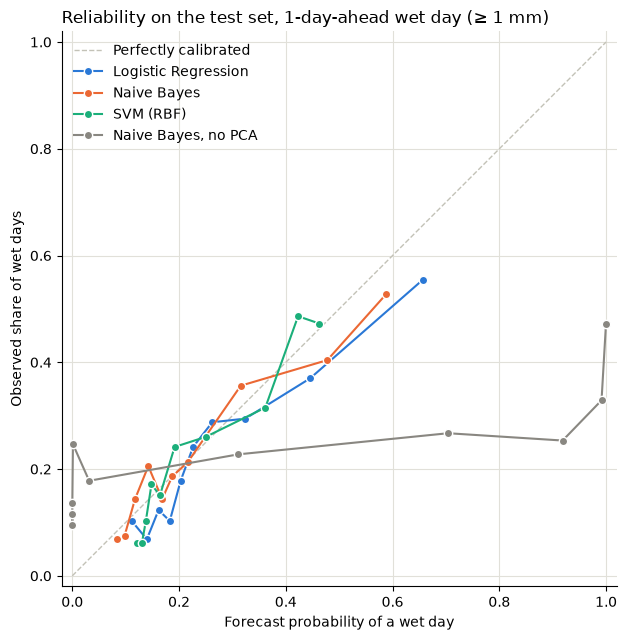

In [ ]:
import matplotlib.pyplot as plt
from sklearn.calibration import calibration_curve

# One fixed colour per model; the uncorrected Naive Bayes is muted gray
curves = {
    "Logistic Regression": (prob_test["Logistic Regression"], "#2a78d6"),
    "Naive Bayes": (prob_test["Naive Bayes"], "#eb6834"),
    "SVM (RBF)": (prob_test["SVM (RBF)"], "#1baf7a"),
    "Naive Bayes, no PCA": (nb_models["No PCA"].predict_proba(Xp_test)[:, 1], "#898781"),
}

fig, ax = plt.subplots(figsize=(7, 6.5))
ax.plot([0, 1], [0, 1], color="#c3c2b7", linewidth=1, linestyle="--", label="Perfectly calibrated")
for name, (p, color) in curves.items():
    observed, forecast = calibration_curve(wet_test, p, n_bins=10, strategy="quantile")
    ax.plot(forecast, observed, color=color, linewidth=1.5, marker="o", markersize=6,
            markeredgecolor="white", markeredgewidth=1, label=name)

ax.set_xlim(-0.02, 1.02)  # small margin so points at 0 and 1 stay visible
ax.set_ylim(-0.02, 1.02)
ax.set_aspect("equal")
ax.set_xlabel("Forecast probability of a wet day")
ax.set_ylabel("Observed share of wet days")
ax.set_title(f"Reliability on the test set, {h}-day-ahead wet day (≥ {WET_MM:g} mm)", loc="left")
ax.grid(color="#e1e0d9", linewidth=0.8)
ax.set_axisbelow(True)
for side in ("top", "right"):
    ax.spines[side].set_visible(False)
ax.legend(frameon=False, loc="upper left")

plt.tight_layout()
plt.show()

## Amount: Gamma GLM
Wet-day amounts are positive and right-skewed, and the Gamma distribution is the standard model for them. A Gamma GLM with log link predicts $\mu_{wet} = \exp(w^\top x + b)$, which is always positive. It is fitted on the wet target days of the training set only, then combined with the occurrence model that has the best validation BSS.

**Metrics for amounts.** We rank amount forecasts by RMSE and by the MSE skill score against climatology, $1 - \text{MSE} / \text{MSE}_{climatology}$. MAE is shown but it is misleading here: it is minimised by the median, which is close to 0 mm on most days, so forecasting 0 mm every day gets the lowest MAE although it never predicts any rain. The hurdle forecast $p\,\mu_{wet} + (1 - p)\,\mu_{dry}$ is an expected value, which is the forecast that minimises the squared error.

References: monthly climatology (mean of all days in the target month), persistence (tomorrow = today), always 0 mm, and a linear regression fitted directly on `tp_mm` as for temperature.

In [ ]:
from sklearn.linear_model import GammaRegressor, LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error

wet_rows = yp_train >= WET_MM
gamma_glm = make_pipeline(StandardScaler(), GammaRegressor(max_iter=1000))
gamma_glm.fit(Xp_train[wet_rows], yp_train[wet_rows])  # wet target days only

# Wet days of the validation set: the GLM against a constant (mean wet-day amount of the training set)
val_rows = yp_val >= WET_MM
for name, pred in [("Gamma GLM", gamma_glm.predict(Xp_val[val_rows])),
                   ("Constant mean", np.full(val_rows.sum(), yp_train[wet_rows].mean()))]:
    print(f"Wet validation days, {name:<13}: MAE {mean_absolute_error(yp_val[val_rows], pred):.2f} mm, "
          f"RMSE {mean_squared_error(yp_val[val_rows], pred) ** 0.5:.2f} mm")

mu_dry = yp_train[~wet_rows].mean()  # mean amount on dry days (below 1 mm)
best_occ = max(["Logistic Regression", "Naive Bayes", "SVM (RBF)"],
               key=lambda m: occurrence_metrics(wet_val, prob_val[m], prob_val["Climatology"])["BSS"])
print(f"Occurrence model with the best validation BSS: {best_occ}")

clim_tp = yp_train.groupby(target_month(yp_train)).mean()  # mean precipitation per month, all days
direct_lr = LinearRegression().fit(Xp_train, yp_train)

def amount_forecasts(X, y, prob):
    return {
        "Climatology": target_month(y).map(clim_tp).to_numpy(),
        "Persistence": X["tp_mm"].to_numpy(),
        "Always 0 mm": np.zeros(len(y)),
        "Linear Regression on tp_mm": direct_lr.predict(X),
        f"Hurdle: {best_occ} + Gamma GLM": prob[best_occ] * gamma_glm.predict(X) + (1 - prob[best_occ]) * mu_dry,
    }

def amount_metrics(y, pred, pred_clim):
    mse = mean_squared_error(y, pred)
    return {"RMSE (mm)": mse ** 0.5, "MSE skill": 1 - mse / mean_squared_error(y, pred_clim),
            "MAE (mm)": mean_absolute_error(y, pred)}

amount_val = amount_forecasts(Xp_val, yp_val, prob_val)
amount_test = amount_forecasts(Xp_test, yp_test, prob_test)

amount_rows = {}
for name in amount_val:
    amount_rows[(name, "Validation")] = amount_metrics(yp_val, amount_val[name], amount_val["Climatology"])
    amount_rows[(name, "Test")] = amount_metrics(yp_test, amount_test[name], amount_test["Climatology"])
display(pd.DataFrame(amount_rows).T.round(4))

negative = np.mean(amount_test["Linear Regression on tp_mm"] < 0)
print(f"Linear Regression on tp_mm forecasts negative precipitation on {negative:.1%} of the test days")

Wet validation days, Gamma GLM    : MAE 3.72 mm, RMSE 5.22 mm
Wet validation days, Constant mean: MAE 3.80 mm, RMSE 5.28 mm
Occurrence model with the best validation BSS: Logistic Regression


RMSE (mm)  MSE skill  \
Climatology                             Validation     3.5623     0.0000   
                                        Test           3.7617     0.0000   
Persistence                             Validation     4.3740    -0.5077   
                                        Test           4.6922    -0.5559   
Always 0 mm                             Validation     3.8839    -0.1887   
                                        Test           4.0477    -0.1579   
Linear Regression on tp_mm              Validation     3.4075     0.0850   
                                        Test           3.5998     0.0842   
Hurdle: Logistic Regression + Gamma GLM Validation     3.4112     0.0830   
                                        Test           3.6006     0.0838   

                                                    MAE (mm)  
Climatology                             Validation    1.9977  
                                        Test          2.0095  
Persistence                             Validation    2.0402  
                                        Test          1.9118  
Always 0 mm                             Validation    1.5293  
                                        Test          1.4364  
Linear Regression on tp_mm              Validation    1.8652  
                                        Test          1.8761  
Hurdle: Logistic Regression + Gamma GLM Validation    1.8614  
                                        Test          1.8677

Linear Regression on tp_mm forecasts negative precipitation on 1.2% of the test days


### Forecasts on the last test year
Top: observed precipitation on each target day. Bottom: forecast probability of a wet day from the selected occurrence model, with the climatological probability as reference; the dots mark the days that were actually wet.

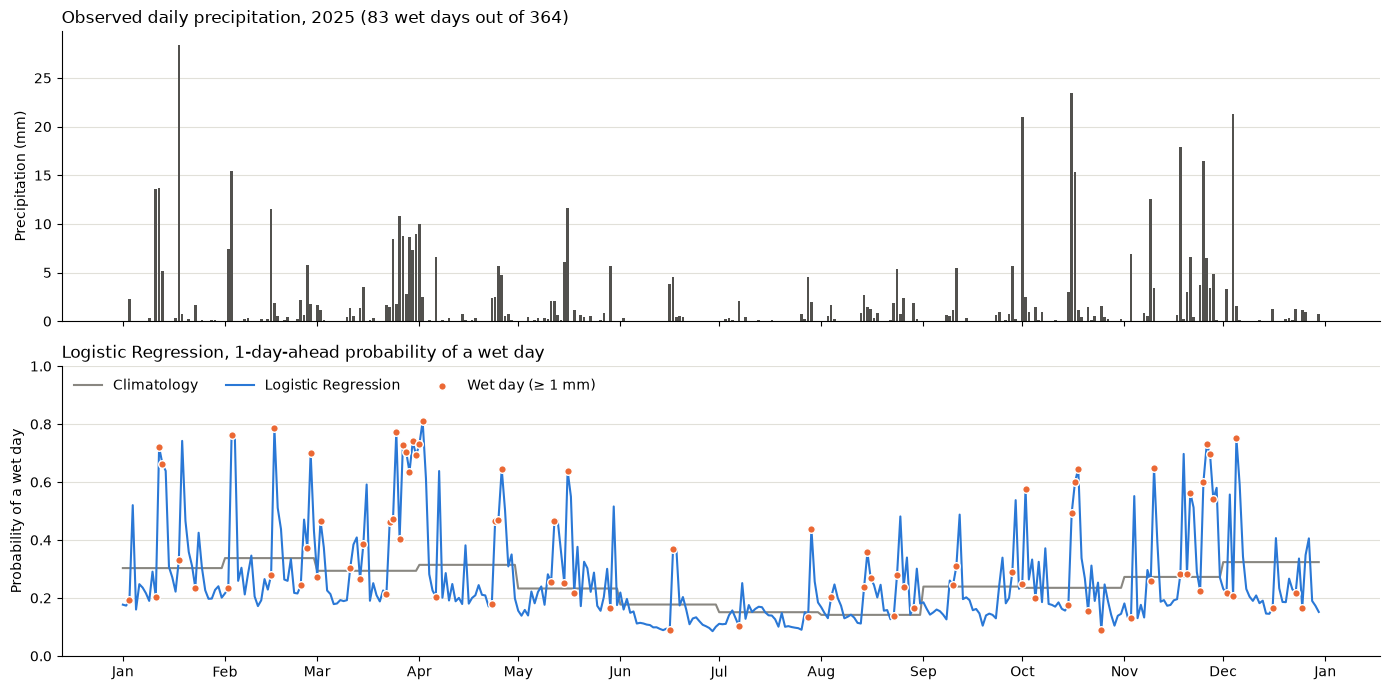

In [ ]:
import matplotlib.dates as mdates

# Plot against the target day t+h, i.e. the day the precipitation refers to
rain_plot = pd.DataFrame({
    "Observed (mm)": yp_test,
    "Forecast": prob_test[best_occ],
    "Climatology": prob_test["Climatology"],
}, index=yp_test.index)
rain_plot.index = rain_plot.index + pd.Timedelta(days=h)
rain_plot = rain_plot.loc[str(rain_plot.index.year.max())]
wet_obs = rain_plot["Observed (mm)"] >= WET_MM

fig, (ax_obs, ax_prob) = plt.subplots(2, 1, figsize=(14, 7), sharex=True)

ax_obs.bar(rain_plot.index, rain_plot["Observed (mm)"], width=0.8, color="#52514e")
ax_obs.set_ylabel("Precipitation (mm)")
ax_obs.set_title(f"Observed daily precipitation, {rain_plot.index.year[0]} "
                 f"({wet_obs.sum()} wet days out of {len(rain_plot)})", loc="left")

ax_prob.plot(rain_plot.index, rain_plot["Climatology"], color="#898781", linewidth=1.5, label="Climatology")
ax_prob.plot(rain_plot.index, rain_plot["Forecast"], color="#2a78d6", linewidth=1.5, label=best_occ)
ax_prob.scatter(rain_plot.index[wet_obs], rain_plot["Forecast"][wet_obs], color="#eb6834", s=30, zorder=3,
                edgecolors="white", linewidths=1, label=f"Wet day (≥ {WET_MM:g} mm)")
ax_prob.set_ylim(0, 1)
ax_prob.set_ylabel("Probability of a wet day")
ax_prob.set_title(f"{best_occ}, {h}-day-ahead probability of a wet day", loc="left")
ax_prob.legend(frameon=False, loc="upper left", ncol=3)
ax_prob.xaxis.set_major_locator(mdates.MonthLocator())
ax_prob.xaxis.set_major_formatter(mdates.DateFormatter("%b"))

for ax in (ax_obs, ax_prob):
    ax.grid(axis="y", color="#e1e0d9", linewidth=0.8)
    ax.set_axisbelow(True)
    for side in ("top", "right"):
        ax.spines[side].set_visible(False)

plt.tight_layout()
plt.show()

### Summary
- All three classifiers beat both reference forecasts one day ahead and end up close to each other: on the test set BSS ≈ 0.11 and AUC ≈ 0.72–0.73, against a BSS of 0.09 for persistence. Logistic regression has the best validation BSS and is the simplest, so it is the occurrence part of the hurdle model.
- Naive Bayes only works after decorrelating the features (validation BSS from −0.74 to +0.09). The SVM needs balanced class weights, and Platt scaling to turn its scores into probabilities.
- Amounts are much harder. On wet days the Gamma GLM barely beats a constant, so almost all the skill of the expected precipitation comes from the occurrence probability. The hurdle model reduces the MSE by about 8% against climatology, the same as a linear regression fitted directly on `tp_mm`; its advantages are forecasts that are never negative and a probability of rain that can be used on its own.
- Forecasting 0 mm every day gets the lowest MAE of all, which is why amounts are ranked by RMSE.
- Three very different classifiers reach almost the same skill, which suggests that the limit is the information in the inputs rather than the model: these are local land-surface variables, without pressure, humidity or wind.